# Data Cleaning

As a Data Scientist, you will spend most time on data cleaning. It is a process which can be annoying sometimes and definitely one you have to do over and over and over again. But it is also one of the most important steps of the data science lifecycle since it determines the quality of your data. Remember the "garbage in, garbage out" concept! Therefore it has a huge impact on your prediction model later on and is time well spent. Most of the data you will see in this course is already pretty much cleaned up for modelling. In a business context, this is usually not the case.

In this notebook we will learn a few tools which can be helpful while cleaning your data. Also we will learn some techniques how to handle missing data.

## Learning Objectives

At the end of this notebook, you should be able to:

* Inspect your data and use the general pandas function for the first analyses
* Handle missing data and use some imputing techniques
* Know when to drop data
* Transform your data.

## Preliminary data cleaning

As it gets probably usual by now, we import our most needed libraries.

In [1]:
import numpy as np
import pandas as pd

Let's load the data from `seattle-weather_raw.csv` into a pandas data frame. You might already know this dataset from the pandas exercises notebooks. We gave you the dataset preprocessed. Now it's the raw file and we need to give it some thought to clean it up.

In [2]:
# importing raw data
df_weather = pd.read_csv("data/seattle-weather_raw.csv")

> **Exercise:**
>
> Get a quick overview of the data. Use the learned pandas methods like `.head()`, `.tail()`, `.info()` and `.describe()`. Is there anything you notice? What would you address in the data cleaning process?

<details><summary>
Click here for a hint…
</summary>
Do you see some:
  
    - formatting problems in the column names?
    - duplicates? 
    - missing values? (what is the reason? and what can you do about it?)
    - inconsistency in the meaning of data?
    - different unit for data?
    - different data types than expected?
    - obvious outliers/ unexpected values?
</details>


In [3]:
# your code: check for data types and statistics overview of data frame columns
# size of the table: (rows, columns)
print(df_weather.shape)
# one line per column: name, how many values are filled, data type
df_weather.info()

(1498, 6)
<class 'pandas.DataFrame'>
RangeIndex: 1498 entries, 0 to 1497
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           1498 non-null   str    
 1   Precipitation  1396 non-null   str    
 2   Temp Max       1144 non-null   float64
 3   Temp Min       1498 non-null   str    
 4   Wind           1498 non-null   float64
 5   -              1498 non-null   str    
dtypes: float64(2), str(4)
memory usage: 70.3 KB


In [4]:
# first rows: do the values look the way the column name promises?
df_weather.head()

,Date,Precipitation,Temp Max,Temp Min,Wind,-
0,2012/01/01,0.0,12.8,41.0 F,4.710858,drizzle
1,2012/01/02,10.9,NaN,37.04 F,4.527453,r
2,2012/01/03,0.8,11.7,44.96 F,2.315752,r.
3,2012/01/03,0.8,11.7,44.96 F,2.315752,r.
4,2012/01/04,20.3,12.2,42.08 F,4.719543,r


In [5]:
# last rows: does the file end cleanly, or with junk lines?
df_weather.tail()

,Date,Precipitation,Temp Max,Temp Min,Wind,-
1493,2015/12/27,8.6,4.4,35.06 F,2.927153,Fog
1494,2015/12/28,1.5,5.0,35.06 F,1.314164,Fog
1495,2015/12/29,0.0,7.2,33.08 F,2.603683,Fog
1496,2015/12/30,0.0,5.6,30.2 F,3.436422,s.
1497,2015/12/31,0.0,NaN,28.22 F,3.517035,sun


In [6]:
# statistics for the number columns (only 2 of 6 show up: a warning sign)
df_weather.describe()

,Temp Max,Wind
count,1144.000000,1498.000000
mean,16.448601,3.253177
std,7.415653,1.439365
min,-1.600000,0.431362
25%,10.600000,2.228335
50%,15.600000,3.003751
75%,22.200000,4.032462
max,35.600000,9.512011


In [7]:
# statistics for the text columns: count, distinct values, most frequent value
df_weather.describe(include="str")

,Date,Precipitation,Temp Min,-
count,1498,1396,1498,1498
unique,1461,108,55,20
top,2012/01/03,0.0,42.980000000000004 F,s
freq,2,807,71,195


In [8]:
# three quick counts: missing values per column, fully identical rows, weather labels
print("missing values per column:")
print(df_weather.isna().sum())
print()
print("identical rows:", df_weather.duplicated().sum())
print("different weather labels:", df_weather["-"].nunique())

missing values per column:
Date               0
Precipitation    102
Temp Max         354
Temp Min           0
Wind               0
-                  0
dtype: int64

identical rows: 37
different weather labels: 20


**My answer: what I notice and would clean**

| What I see | Where | What I would do |
|---|---|---|
| Column names have capitals and spaces, the last one is just `-` | header | lower case, underscores, rename `-` to `weather` |
| 1498 rows, but only 1461 different dates (4 years = 1461 days) | `Date` | 37 identical rows: drop the duplicates |
| Dates are stored as text | `Date` | convert to a real date type |
| Rain amounts are stored as text, so something that is not a number hides in there | `Precipitation` | find it, replace it, convert to float |
| Values carry a unit (`41.0 F`) and are Fahrenheit, while `Temp Max` is Celsius | `Temp Min` | strip the unit, convert to float, convert to Celsius |
| Many decimals nobody needs | `Wind` | round |
| 20 labels for about 5 kinds of weather (`r`, `r.`, `rain`, `Rain`) | `-` | map every spelling to one label |
| Missing values: 354 in `Temp Max`, 102 in `Precipitation` (counted before the duplicates are removed) | both | look for a pattern, then drop or fill |
| No impossible values: `Temp Max` runs from -1.6 to 35.6, wind from 0.4 to 9.5 | number columns | nothing to fix |

In [9]:
df_weather.head(7)

,Date,Precipitation,Temp Max,Temp Min,Wind,-
0,2012/01/01,0.0,12.8,41.0 F,4.710858,drizzle
1,2012/01/02,10.9,NaN,37.04 F,4.527453,r
2,2012/01/03,0.8,11.7,44.96 F,2.315752,r.
3,2012/01/03,0.8,11.7,44.96 F,2.315752,r.
4,2012/01/04,20.3,12.2,42.08 F,4.719543,r
5,2012/01/05,1.3,NaN,37.04 F,6.124592,rain
6,2012/01/06,2.5,4.4,35.96 F,2.216936,r.


Let's get started!

## Fix column names formats

As you are probably aware of, we have to change the column names. As already explained in earlier notebooks, it is always a good idea to change the empty spaces to underscores. Also it is recommended to use only lowercase letters in the column names. Furthermore the last column has no name.

One way to change the names is to write the actual names into a list, editing them and transfer the list back to the data frame, as it is explained in the pandas notebooks. But it is also possible to edit the column names in the data frame directly. Of course in the end you can use the way which you feel is the most comfortable.

The `.str` function allows you to use string functions on a data frame column. We can use that to simply replace empty spaces with an underscore.

In [10]:
# replacing empty spaces with underscores in column names
df_weather.columns = df_weather.columns.str.replace(" ", "_")
df_weather.columns

Index(['Date', 'Precipitation', 'Temp_Max', 'Temp_Min', 'Wind', '-'], dtype='str')

In the same way we can just simply tell our data frame to only use lower cases for our column names.

In [11]:
# changing all column names to lower case
df_weather.columns = df_weather.columns.str.lower()
df_weather.columns

Index(['date', 'precipitation', 'temp_max', 'temp_min', 'wind', '-'], dtype='str')

We also could use `.str` for renaming the last column name. But pandas has already the `.rename` function build in. That way we can iterate directly into the column names and only need a dictionary to change the names.

In [12]:
# renaming last column
df_weather = df_weather.rename({"-": "weather"}, axis=1)
df_weather.columns

Index(['date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather'], dtype='str')

Congratulations. You just finished the first step of cleaning this data frame. Let's have another look at the first rows again. What else can you see which is odd?

In [13]:
df_weather.head(5)

,date,precipitation,temp_max,temp_min,wind,weather
0,2012/01/01,0.0,12.8,41.0 F,4.710858,drizzle
1,2012/01/02,10.9,NaN,37.04 F,4.527453,r
2,2012/01/03,0.8,11.7,44.96 F,2.315752,r.
3,2012/01/03,0.8,11.7,44.96 F,2.315752,r.
4,2012/01/04,20.3,12.2,42.08 F,4.719543,r


## Dealing with duplicates

The rows with index $2$ and $3$ are identical. There are obviously duplicated which can happen for example while merging two data frames together. The function `.duplicated()` returns a boolean pandas Series which tells you if a row is a duplicate or not. Combined with another well known function it will tell us how many duplicated rows we have.

In [14]:
# check how many duplicated rows exist in the data frame
df_weather.duplicated().value_counts()

False    1461
True       37
Name: count, dtype: int64

As you can see we have 37 duplicated rows. Those rows can be easily dropped. Furthermore we have to drop the old index and renew them.

In [15]:
# remove duplicates
df_weather = df_weather.drop_duplicates()
# reset index inplace
df_weather.reset_index(inplace=True, drop=True)
df_weather.head(5)

,date,precipitation,temp_max,temp_min,wind,weather
0,2012/01/01,0.0,12.8,41.0 F,4.710858,drizzle
1,2012/01/02,10.9,NaN,37.04 F,4.527453,r
2,2012/01/03,0.8,11.7,44.96 F,2.315752,r.
3,2012/01/04,20.3,12.2,42.08 F,4.719543,r
4,2012/01/05,1.3,NaN,37.04 F,6.124592,rain


## Data Types and Transforming Data

One Part of Data Cleaning is to get the data types into the right shape. This is important so we can work better with the data later on. The dtype `object` means that there are several data types in the corresponding column.

In [16]:
# check data types in data frame
df_weather.dtypes

date                 str
precipitation        str
temp_max         float64
temp_min             str
wind             float64
weather              str
dtype: object

Let's go through the column list and start at the beginning with the **Date** column. At the moment it has the data type `Object`. We will look at this more closely to see what data type Pandas identifies our current date entry as. To do this, we can simply take the first entry.

In [17]:
# type of first date entry
type(df_weather["date"][0])

str

As you can see our date entry is just a string. We can change that to a date time very easy as we already learned. Note that you also could do that in the beginning, when you read in the csv file with the parameter `parse_date=['date']`.

In [18]:
# change "date" dtype to datetime with format %Y/%m/%d
df_weather["date"] = pd.to_datetime(df_weather["date"], format="%Y/%m/%d")

A quick check if that worked:

In [19]:
# check "date" dtype
type(df_weather["date"][0])

pandas.Timestamp


Moving on to the column **precipitation**. At the look of the data frames head, we would have expected a float datatype. This is actually an indication, that there is more than just numbers in this column. For now we could just try to convert the column to the float type, also this might not work.

In [20]:
# change data type to float
df_weather = df_weather.astype({"precipitation": float})

ValueError: could not convert string to float: '$': Error while type casting for column 'precipitation'

As expected we get an error message. However this can help us to determine why our column cannot be assigned to the data type `float`. If we read the message it tells us in the last line that we can not convert a string to a float. Also now we know the cause of our error. Somewhere in this column is a `$`-character hidden. Out of curiosity let's try to find it.

In [21]:
# display rows with "$" in precipitation column
df_weather.query('precipitation == "$"')

,date,precipitation,temp_max,temp_min,wind,weather
1130,2015-02-04,$,10.6,39.92 F,1.705199,f


It is only one `$`-character in line $1130$. We can easily replace the `$`-character with a numpy nan value. nan stands for "Not a Number" and is used as a placeholder for missing values. Afterwards we are able to convert our column data type.

In [22]:
# replace the `$`-character with a numpy NaN value
df_weather["precipitation"] = df_weather.precipitation.replace("$", np.nan)
# change data type to float
df_weather = df_weather.astype({"precipitation": float})
df_weather.precipitation.dtypes

dtype('float64')

Looking at our data types and the table head again, the `temp_max`-column looks good. But if we continue with `temp_min` we will notice two things. First there are not only numbers in `temp_min` (dtype is detected as object) and the minimum temperature is larger as the maximum temperature. We can assume that somehow the units of the temperature got mixed up. The maximum temperature is in Celsius while the minimum is appearing to be in Fahrenheit. To fix that we can first delete the unit from the number and change the data type.

In [23]:
# remove unit from "temp_min" column, change dtype to float
df_weather["temp_min"] = df_weather.temp_min.str.strip(" F").astype("float")
df_weather.temp_min.dtype

dtype('float64')

Now that we have floats in our column we can convert the temperature from Fahrenheit to Celsius.

In [24]:
# convert temp_min to celsius
df_weather["temp_min"] = df_weather.temp_min.apply(lambda x: (x - 32) / 1.8)
df_weather.head(5)

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.710858,drizzle
1,2012-01-02,10.9,NaN,2.8,4.527453,r
2,2012-01-03,0.8,11.7,7.2,2.315752,r.
3,2012-01-04,20.3,12.2,5.6,4.719543,r
4,2012-01-05,1.3,NaN,2.8,6.124592,rain


That is much better. Also the minimum temperature is now smaller than the maximum temperature.

For the "Wind" column, the data type is already as it should be. However, you should round these numbers for the future. It might be good to have a few decimal places for future modelling, but it is not always necessary to be so precise. Let's therefore try rounding these numbers for practice purposes.

In [25]:
# rounding wind data
df_weather["wind"] = df_weather.wind.round(2)
df_weather.head(5)

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.71,drizzle
1,2012-01-02,10.9,NaN,2.8,4.53,r
2,2012-01-03,0.8,11.7,7.2,2.32,r.
3,2012-01-04,20.3,12.2,5.6,4.72,r
4,2012-01-05,1.3,NaN,2.8,6.12,rain


Last column doesn't contain a number but a string, which describes the type of weather. That kind of data is called a categorical value. We can find out how many categorical values there are.


In [26]:
# display number of distinct elements
df_weather.weather.nunique()

20

That is quite a lot, but also as you may noticed not accurate. We have various entries which mean the same thing.

In [27]:
# display all distinct elements
df_weather["weather"].unique()

<StringArray>
['drizzle',       'r',      'r.',    'rain',       's',    'Rain',     'sun',
     'Sun',    'Snow',     'sn.',      'sw',       'd',      's.',   'driz.',
    'snow', 'Drizzle',     'Fog',       'f',      'f.',     'fog']
Length: 20, dtype: str

Looking at the unique values, we see that "drizzle", "d", "d." and "drizzle" all probably represent the same category. So one category has several values. This often happens if there is no fixed standard for data collection. We need to reduce the number of values for each category to one. The easiest and safest way is to manually assign each value to the appropriate category. The implemented function `.map` uses either a dictionary to assign a value to it's new one or a function, which is applied on each value. In our case we will use the dictionary.

> [!NOTE]
> Sometimes it can happen that abbreviations are ambiguous. For example, there is a category "sn" which could represent either "snow" or "sun". Here it is worth diving deeper into the data collection process to make a more informed decision.

> You could also use pattern match (which uses regular expressions) or fuzzy matching to approach this task. But they are more complicated to program and an absolute understanding of them is mandatory, because there is a risk of assigning a value to the wrong category.

In [28]:
# reducing number of categorical values by mapping with a word-dictionary
df_weather["weather"] = df_weather["weather"].map(
    {
        "drizzle": "drizzle",
        "r": "rain",
        "r.": "rain",
        "rain": "rain",
        "s": "sun",
        "Rain": "rain",
        "sun": "sun",
        "Sun": "sun",
        "Snow": "snow",
        "sn.": "snow",
        "sw": "snow",
        "d": "drizzle",
        "s.": "sun",
        "driz.": "drizzle",
        "snow": "snow",
        "Drizzle": "drizzle",
        "Fog": "fog",
        "f": "fog",
        "f.": "fog",
        "fog": "fog",
    }
)
df_weather.weather.unique()

<StringArray>
['drizzle', 'rain', 'sun', 'snow', 'fog']
Length: 5, dtype: str

We can convert the data type from this column to `string` just as easily as before. Note that this is not mandatory going forward.

In [29]:
# convert to dtype "string"
df_weather["weather"] = df_weather.weather.astype("string")
df_weather.weather.dtype

<StringDtype(storage='python', na_value=<NA>)>

## Missing Data and Imputing

Missing data is a common problem when working with real data sets. The reasons for missing data can be manifold, e.g. sensor failures, old data, improper data management and even human error. 

It is important that missing data is identified and dealt with appropriately before further data analysis or machine learning. Many machine learning algorithms cannot handle missing data and require that entire rows or columns where a single missing value is present be deleted. Or missing data has to be replaced (imputed) with a new value.

Knowing when missing data occurs can help avoid missing values in the future, or help in dealing with them.
There is a great python library for doing some EDA specifically for missing data, called **[missingno](https://github.com/ResidentMario/missingno)**. (Do not confuse it with the pokemon of the same name.)

<img src="https://www.pokewiki.de/images/2/28/Tokiya_Missingno.jpg" alt="drawing" style="width:250px;"/>



In [30]:
# import missingno
import missingno as msno

We can have a look at how many values are missing per column in our data.

In [31]:
# display number of missing values per column
df_weather.isna().sum()

date               0
precipitation    101
temp_max         349
temp_min           0
wind               0
weather            0
dtype: int64

With missingno we can simply display these values as missing percentages per column in a bar chart. Each bar represents one column. On the left side we see the percentage of data present, on the right side we see the exact number of values that correspond to these percentages.

<Axes: >

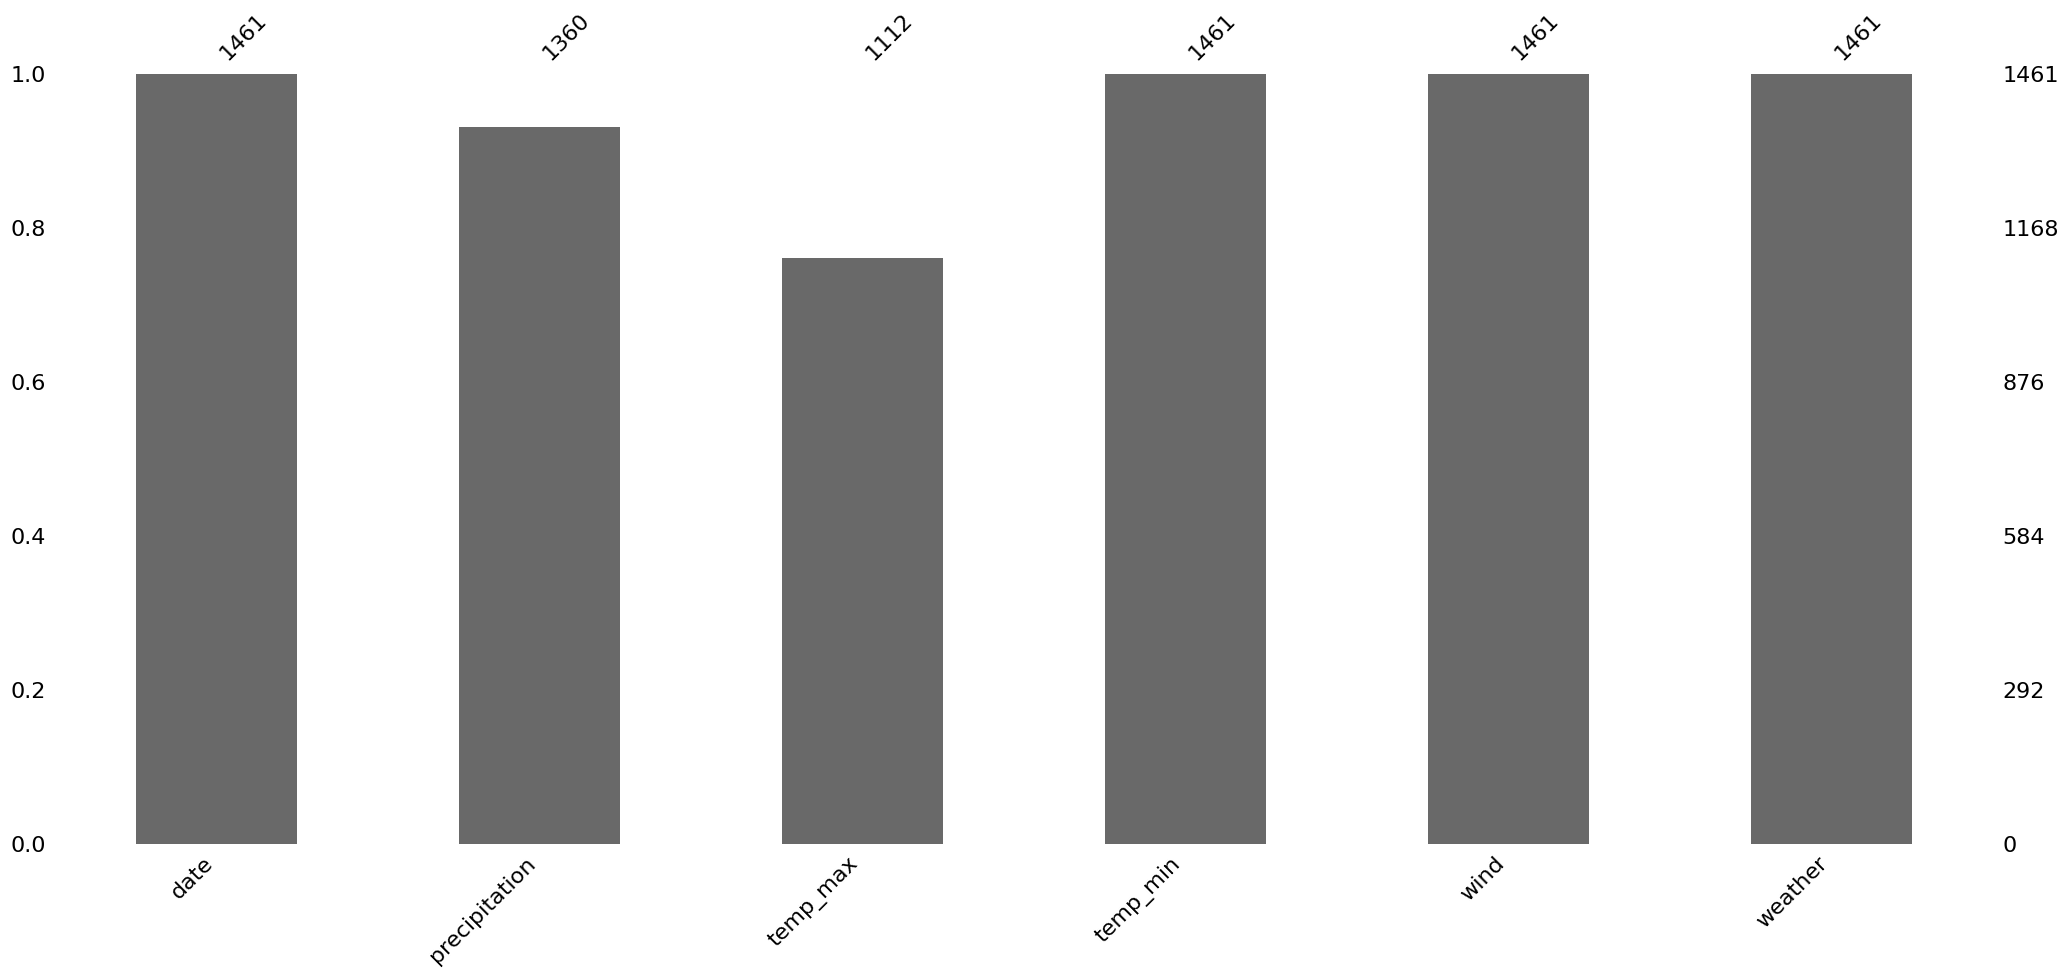

In [32]:
# plotting percentage of missing values per column
msno.bar(df_weather)

We see that only two columns contain missing values: More than 20 % of the data is missing in the column "temp_max". Less than 10 % of the data is missing in the column "precipitation". It would be interesting to know if there is a pattern in the occurrence of the missing values. This would help us understand where they are coming from. For example, it could be that these values are not collected on Sunday. Then we would have a missing value in every 7th row. It could also show us a period when our instrument stopped working, which would then lead to successive missing values. All this helps us to understand our data better and to correct errors if necessary.

With missingno you can also print a matrix plot. For each row in the dataset you can see if data is missing in each column. When data is present, the plot is shaded in grey (or your color of choice), and when it is absent the plot is displayed in white. This gives you an view how that missing data is distributed in the data frame. And if they occur together.

<Axes: >

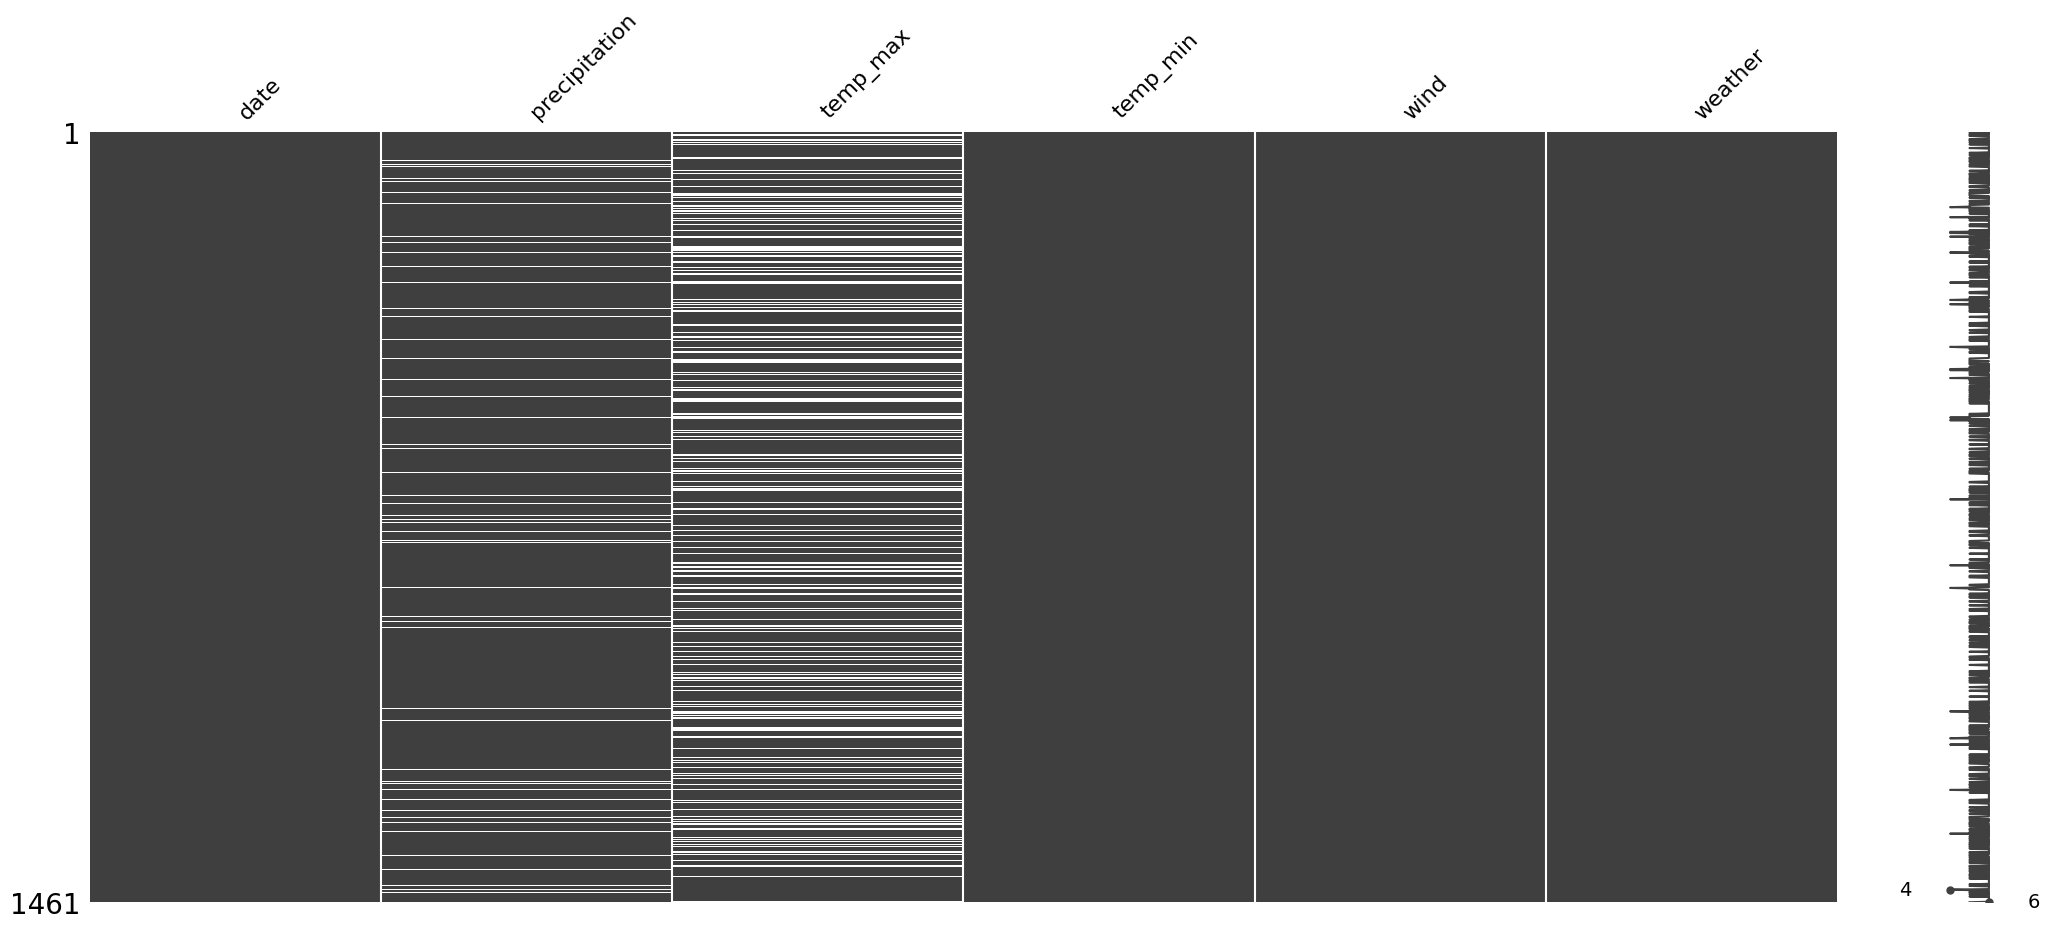

In [33]:
msno.matrix(df_weather)

On the right hand side you can see for each data point how many columns contain data. In our case, the range is from 4 columns with data (left) to 6 columns with data (right). As you can see, there are not many rows where missing values occur together. And overall, there is no clear pattern in the missing data. Therefore, we have to assume, that the missing data occurs randomly. Which is not helping us at all on how to best treat this missing values. 

Missingno has more plots to investigate missing values. For example, you can also create a heatmap to see how often missing values in specific features occur together. Check out the repo for more insights!

### Imputing Data

Missing Data and Imputing are big topics in data science. Imputing means to replace missing values with sensible values. There are several imputing techniques that we will familiarize ourselves with in this notebook. When you impute missing values, you are manipulating the data and this can have a significant impact on the quality of the data.  Hence you need to have a certain level of knowledge about your data in order to find a good solution and the approach that is best suited for the task at hand. As usual in data science, there is no one solution that fits all problems. Imputation of data ranges from fairly simple to highly complex strategies. Remember that the work of a data scientist progresses in cycles. It is always best to start with a simple approach and become more complex with each cycle. With this in mind, your pre-processing will only become more complex and thus more time-consuming if it really provides more value.

The first step is always to determine how many missing data you got. Since we already identified all our missing data above, we only have to use one command.

> Exercise: Time for brainstorming! What could be reasons for missing values and what different ways of dealing with missing data can you think of? Are these possibilities dependent on the reasons of missing values?

**My answer: reasons for missing values, and ways to deal with them**

Reasons:

- The value was never measured: a broken sensor, a power cut, a day nobody was on duty.
- The value was measured but lost: a typing mistake, a failed export, a merge of two tables that did not match.
- The value was left out on purpose: a question someone did not want to answer.
- The value cannot exist: "snow depth" on a day without snow.
- The value was unreadable and turned into a gap during cleaning (our `$` in `precipitation`).

Ways to deal with them:

- Drop the rows, or drop the whole column.
- Fill with one fixed value, or with a flag that says "this was missing".
- Fill with the mean, median or most frequent value of the column.
- Fill from the neighbours: the value before, the value after, or a line between them (interpolation).
- Predict the value with a model from the other columns.
- Go back to the source and get the real value. Often the best option, rarely possible.

Yes, the right way depends on the reason:

- Gaps spread at random: dropping or simple filling does little harm.
- Gaps that follow a pattern (always Sundays, always very cold days): dropping removes one kind of day and bends the data. The gap itself carries information, so a flag is better.
- Values that cannot exist should stay empty or get their own label. Inventing a number would be wrong.
- Data in time order (like our weather) has helpful neighbours: yesterday and tomorrow are good hints.

### Dropping data

Dropping data is the easiest and fastest option. But this is only recommended if there’s a lot of data to start with and the percentage of missing values is low. There are multiple ways to drop your data. You could drop the rows which have missing values in them or even drop a whole column.

Though you could end up with little data if you have too much missing data. You also could loose some (valuable) information or maybe evan change the representation of some data if the rows with missing values have something in common and are not totally random. Hence you should always be mindful about dropping your data.

In our case we have only 2 columns with missing values and the amount doesn't seem too much. But let's put those numbers in context.

In [34]:
print(f"numbers of rows : {df_weather.shape[0]}")
print(
    f"missing values in precipitation : {round(df_weather.precipitation.isna().sum() / df_weather.shape[0] * 100, 2)} %"
)
print(
    f"missing values in temp_max : {round(df_weather.temp_max.isna().sum() / df_weather.shape[0] * 100, 2)} %"
)
print(
    f"missing values in data frame : {round(df_weather.isna().sum().sum() / (df_weather.shape[0] * df_weather.shape[1]) * 100, 2)} %"
)

numbers of rows : 1461
missing values in precipitation : 6.91 %
missing values in temp_max : 23.89 %
missing values in data frame : 5.13 %


We have 1461 rows and about one quarter of them have missing values in at least one column. This would actually be too much to drop. Fortunately there are more ways of imputing. But for a start dropping is still a possibility.

Pandas has a function for dropping missing values. You will find a description and an explanation for a few attributes in the following table:

`dropna` | description
---|---
`.dropna()` | drops row if contains at least 1 NaN
`.dropna(how='all')` | drops row if all entries are filled with NaN
`.dropna(thresh=2)` | drops row if there are less than 2 cells filled with a valid value

You can also check out the [documentation for `dropna`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.dropna.html).

> **Exercise:** Since we also want to show you other ways of imputing in this notebook, make a copy of our dataset. After that use `.dropna` on our copied data set. Try at least two different ways.


In [35]:
# create a copy of the dataset
# .copy() gives us a separate table, so df_weather itself stays untouched
df_drop = df_weather.copy()

# drop all rows if they contain at least one missing value (in any column)
df_drop_any = df_drop.dropna()
print("rows before        :", df_drop.shape[0])
print("rows after dropna():", df_drop_any.shape[0])
print("rows lost          :", df_drop.shape[0] - df_drop_any.shape[0])
print("missing values left:", df_drop_any.isna().sum().sum())

rows before        : 1461
rows after dropna(): 1035
rows lost          : 426
missing values left: 0


In [36]:
# way 2: drop a row only if ALL of its cells are empty
# no row is completely empty here, so nothing is dropped
df_drop_all = df_drop.dropna(how="all")
print("rows after dropna(how='all')   :", df_drop_all.shape[0])

# way 3: keep a row only if at least 5 of its 6 cells are filled
# this drops only the rows where both values are missing
df_drop_thresh = df_drop.dropna(thresh=5)
print("rows after dropna(thresh=5)    :", df_drop_thresh.shape[0])

# way 4: look at one column only: drop rows without a precipitation value
df_drop_subset = df_drop.dropna(subset=["precipitation"])
print("rows after dropna(subset=prec.):", df_drop_subset.shape[0])

# way 5: drop the columns that have gaps, instead of the rows
df_drop_cols = df_drop.dropna(axis=1)
print("columns after dropna(axis=1)   :", list(df_drop_cols.columns))

rows after dropna(how='all')   : 1461
rows after dropna(thresh=5)    : 1437
rows after dropna(subset=prec.): 1360
columns after dropna(axis=1)   : ['date', 'temp_min', 'wind', 'weather']


In [37]:
# does dropping change the picture? compare the weather mix before and after
weather_mix = pd.DataFrame(
    {
        "all rows %": df_drop.weather.value_counts(normalize=True) * 100,
        "after dropna %": df_drop_any.weather.value_counts(normalize=True) * 100,
    }
).round(1)
weather_mix

,all rows %,after dropna %
weather,,
sun,48.9,50.7
fog,28.1,27.7
rain,17.7,16.7
drizzle,3.7,3.5
snow,1.6,1.4


**My answer:** `dropna()` is the simplest way, but it costs 426 of 1461 rows (29 %): 1035 rows remain. The weather mix shifts by less than 2 percentage points, which fits the random pattern we saw in the matrix plot. Still, we would throw away 426 days of good wind and `temp_min` values just to get rid of 450 empty cells. The gentler variants do not solve the problem: `how="all"` drops nothing, `thresh=5` drops only the 24 rows where both values are missing, and `subset` cleans one column only. Dropping the two columns instead (`axis=1`) would lose the rain and the maximum temperature completely. All of these prices are too high here, so we fill the gaps instead.

### Imputing with a constant

#### Flag the missing value

Sometimes even a missing value can be informative. For example if you asking a proband for their sex and give them only the option of ticking female or male and their define them selfs as queer, it might conclude in a missing value. You could assume and assign that value to `other` or another categorical value.
For our case we could assign a unique value. For precipitation and temperature this would be a really high absolute value.

#### Mean/Median/Mode imputation

One popular technic of imputing is to take the mean, median or mode value of the column. Which one of those three to take depends on the issue you are dealing with. For example if you are having a categorical value (like sex: 0 for male, 1 for female), taking the mean value would not make any sense. Also taking the mean for a numerical value could be dangerous since outliers could have a huge impact. In that case taking the median could be a better choice.
Of course it is also possible to take assumptions, for example the weather today is the same weather as the day before.

> [!TIP]
> A visualization plot could help you determining which value to take.

As you probably already guessed, pandas has implemented functions for the imputing issue:

`method` | description
---|---
`df.fillna(0)` | replaces all nan in df with one value
`df.fillna({'precipitation': 0, 'temp_min': 0, 'temp_max': 42, 'wind': 0, 'weather': 'no_weather'})` | replaces nan in specific columns with specific values
`df.ffill()` | use value of the day (row) before (forward fill)
`df.bfill()` | use value of the day (row) after (backward fill)
`df.ffill(axis=1)` | copies values from the column before
`df.ffill(limit=1)` | if several values are missing in a row (consecutively), only the first gap is filled with the previous day value, the rest stay as NaN

You can also check out the [documentation for `fillna`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.fillna.html).
 And the [documentation for `bfill`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.bfill.html)

> **Exercise:** Please make a copy from `df_weather` again and fill your missing values. Try at least two different methods. Which values would make sense?

In [38]:
# create a copy of the dataset
df_fill = df_weather.copy()

# which values would make sense? look at the two columns first
print("precipitation: mean", round(df_fill.precipitation.mean(), 2),
      "| median", df_fill.precipitation.median(),
      "| share of dry days", round((df_fill.precipitation == 0).mean() * 100, 1), "%")
print("temp_max     : mean", round(df_fill.temp_max.mean(), 2),
      "| median", df_fill.temp_max.median())

precipitation: mean 2.97 | median 0.0 | share of dry days 53.7 %
temp_max     : mean 16.44 | median 15.6


In [39]:
# use fillna to impute missing values
# method 1: a flag value that cannot be real weather (-999)
df_fill_flag = df_fill.fillna({"precipitation": -999, "temp_max": -999})

# method 2: one typical value per column
# rain: median (most days are dry, a few very wet days pull the mean up)
# temp_max: mean (the values are spread evenly around the middle)
df_fill_typical = df_fill.fillna(
    {
        "precipitation": df_fill.precipitation.median(),
        "temp_max": df_fill.temp_max.mean(),
    }
)

# method 3: forward fill = "today is like yesterday"
# the rows are in date order, so the row before is the day before
df_fill_ffill = df_fill.ffill()

# method 4: backward fill = "today is like tomorrow"
df_fill_bfill = df_fill.bfill()

# check: how many gaps are left after each method?
for name, frame in [("flag -999", df_fill_flag), ("median / mean", df_fill_typical),
                    ("forward fill", df_fill_ffill), ("backward fill", df_fill_bfill)]:
    print(f"{name:14s} missing values left: {frame.isna().sum().sum()}")

flag -999      missing values left: 0
median / mean  missing values left: 0
forward fill   missing values left: 0
backward fill  missing values left: 1


In [40]:
# what did each method do to the temp_max column?
# mean = the centre, std = how much the values spread around it
fill_compare = pd.DataFrame(
    {
        "original (with gaps)": df_fill.temp_max.agg(["mean", "std", "min"]),
        "flag -999": df_fill_flag.temp_max.agg(["mean", "std", "min"]),
        "mean": df_fill_typical.temp_max.agg(["mean", "std", "min"]),
        "forward fill": df_fill_ffill.temp_max.agg(["mean", "std", "min"]),
        "backward fill": df_fill_bfill.temp_max.agg(["mean", "std", "min"]),
    }
).round(2)
fill_compare

,original (with gaps),flag -999,mean,forward fill,backward fill
mean,16.44,-226.13,16.44,16.44,16.48
std,7.43,433.18,6.48,7.36,7.38
min,-1.60,-999.00,-1.60,-1.60,-1.60


**My answer: which values make sense?**

- **Flag (-999):** keeps the information "this was missing", but it wrecks every statistic: the mean of `temp_max` falls from 16.44 to -226.13. Only useful if the flag is filtered out or handled later.
- **Median for `precipitation`:** 53.7 % of all days are dry, so the median is 0. The mean (2.97 mm) is pulled up by a few very wet days and would put a little rain on every missing day.
- **Mean for `temp_max`:** mean (16.44) and median (15.6) are close, so either works. But every gap gets the same value, summer or winter, and the spread of the column shrinks (std 7.43 → 6.48).
- **Forward / backward fill:** uses the day before or after. Weather changes slowly, so this keeps the seasons and almost all of the spread (std 7.36 and 7.38). The backward fill leaves one gap: the very last day has no day after it.

For this weather data, forward fill is the most sensible of the four. The interpolation below goes one step further and uses both neighbours.

#### Interpolation

The final method we want to try out today is calculating the missing values with an interpolation. An interpolation estimates the course of a continuous function between two known points. From this function we can approximate the missing value.

There are multiple ways of interpolation. The most common and also the easiest for a missing value $x_{i}$ is the linear interpolation, where two data points, $(x_{i-1},y_{i-1})$ and $(x_{i+1},y_{i+1})$, are connected by a straight line.

$$
y_{i} = y_{i-1} + \frac{y_{i+1} - y_{i-1}}{x_{i+1} - x_{i-1}}(x_i - x_{i-1})
$$

In our case the maximum temperature is a perfect example. If we use the default settings of pandas `.interpolate` we would get a linear interpolation with an equal spaced distribution. It is also possible to take the date instead.

> **Exercise:** Please make a copy from `df_weather` again and try to do an interpolation for the missing values in the maximum temperature column. You might want to check out the [documentation for `interpolate`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.interpolate.html).

In [41]:
# create a copy of the dataset
df_inter = df_weather.copy()

# interpolate the missing values in temp_max column
# linear = draw a straight line from the last known day to the next known day
df_inter["temp_max"] = df_inter.temp_max.interpolate(method="linear")

print("missing before:", df_weather.temp_max.isna().sum())
print("missing after :", df_inter.temp_max.isna().sum())

# the first days, original next to interpolated
pd.DataFrame(
    {
        "date": df_weather.date,
        "original": df_weather.temp_max,
        "interpolated": df_inter.temp_max,
    }
).head(9)

missing before: 349
missing after : 0


,date,original,interpolated
0,2012-01-01,12.8,12.800000
1,2012-01-02,NaN,12.250000
2,2012-01-03,11.7,11.700000
3,2012-01-04,12.2,12.200000
4,2012-01-05,NaN,8.300000
5,2012-01-06,4.4,4.400000
6,2012-01-07,NaN,6.066667
7,2012-01-08,NaN,7.733333
8,2012-01-09,9.4,9.400000


In [42]:
# second way: use the real dates as the x-axis (method="time")
# for this the dates must be the index of the series
temp_by_date = df_weather.set_index("date").temp_max
temp_time = temp_by_date.interpolate(method="time")

# our days are evenly spaced (one row per day, no day missing),
# so both ways should give the same numbers
biggest_difference = np.abs(temp_time.to_numpy() - df_inter.temp_max.to_numpy()).max()
print("biggest difference linear vs time:", round(biggest_difference, 10))

biggest difference linear vs time: 0.0


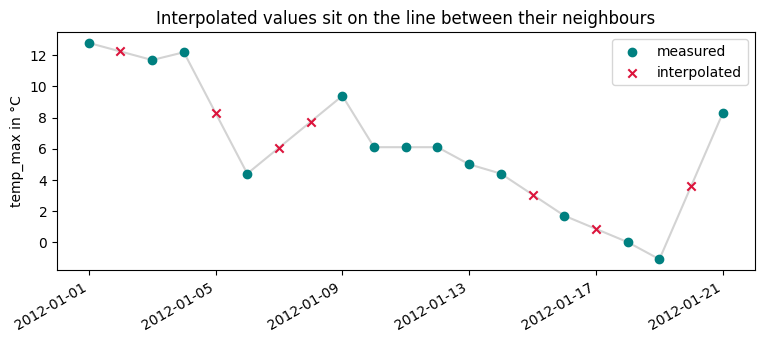

In [43]:
# look at it: three weeks in January 2012, known values and filled values
import matplotlib.pyplot as plt

first_days = df_inter.head(21)
was_missing = df_weather.temp_max.head(21).isna()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(first_days.date, first_days.temp_max, color="lightgrey", zorder=1)
ax.scatter(first_days.date[~was_missing], first_days.temp_max[~was_missing],
           color="teal", label="measured", zorder=2)
ax.scatter(first_days.date[was_missing], first_days.temp_max[was_missing],
           color="crimson", marker="x", label="interpolated", zorder=2)
ax.set_ylabel("temp_max in °C")
ax.set_title("Interpolated values sit on the line between their neighbours")
ax.legend()
fig.autofmt_xdate()
plt.show()

**My answer:** the linear interpolation fills all 349 gaps in `temp_max`. Each missing day gets a value on the straight line between the last and the next measured day (2 January 2012: halfway between 12.8 and 11.7 = 12.25). Because our table has exactly one row per day, the default (`linear`, counts rows) and `method="time"` (counts real days) give the same numbers: the biggest difference is 0.0. If days were missing from the table, only `method="time"` would be correct.

A gap at the very end has no "next" value. pandas then repeats the last measured value (our last row, 2015-12-31). A gap at the very start would stay empty.

**Extra check: which method comes closest?** We cannot see the true values behind the real gaps. But we can run a fair test: hide 200 values that we do know, fill them with each method, and measure how far off each method is.

In [44]:
# fair test: hide 200 known temp_max values, fill them, compare with the truth
rng = np.random.default_rng(42)
known_rows = df_weather.index[df_weather.temp_max.notna()]
hidden_rows = rng.choice(known_rows, size=200, replace=False)

temp_test = df_weather.temp_max.copy()
truth = temp_test[hidden_rows]
temp_test[hidden_rows] = np.nan

candidates = {
    "mean": temp_test.fillna(temp_test.mean()),
    "median": temp_test.fillna(temp_test.median()),
    "forward fill": temp_test.ffill(),
    "linear interpolation": temp_test.interpolate(method="linear"),
}

# average miss in °C: mean of |filled value - true value| over the 200 hidden days
fair_test = pd.Series(
    {name: (filled[hidden_rows] - truth).abs().mean() for name, filled in candidates.items()},
    name="average miss in °C",
).round(2)
fair_test

mean                    6.08
median                  6.10
forward fill            2.46
linear interpolation    1.96
Name: average miss in °C, dtype: float64

**Result of the fair test:** filling with the mean or median misses the true value by about 6 °C on average (6.08 and 6.10). Forward fill misses by 2.46 °C, linear interpolation by 1.96 °C. So for a slowly changing value like temperature, the neighbours are a far better guess than one number for the whole column, and two neighbours beat one.

For `precipitation` this would not hold as well: rain comes in sudden jumps, and a line between a dry day and a very wet day invents a "half wet" day.

Since it is also possible to use splines and polynomials, the interpolation function can be quite powerful. Reading further documentation is absolute necessary to use this function!

### Prediction

It is also possible to predict your missing values. Therefore the column with the missing data would become the target value. The dataset will be split into a set with a valid value for the target which would be used for training and a set with the missing values, for which we would predict. A good model for imputing is KNN. Since we didn't reach the subject of predictive modeling yet, this will only be mentioned at this point.

> [!NOTE]
> It is important to prevent any data leakage! When using a model to impute missing data make sure you remove your actual target values! If you impute temp_max, you cannot use the weather columns when your end goal is to predict the weather.